First five rows:
   sepal_length  sepal_width  petal_length  petal_width species
0           5.1          3.5           1.4          0.2  setosa
1           4.9          3.0           1.4          0.2  setosa
2           4.7          3.2           1.3          0.2  setosa
3           4.6          3.1           1.5          0.2  setosa
4           5.0          3.6           1.4          0.2  setosa

Support vector indices (training set):
[ 83  92  11  20  36  39  64  67  68  79  82  87  88 118   1   5   7  46
  55  59  73  75  78  98]

Support vector indices (original dataset):
[ 43  44  78  72  79  70  83  66  54  85  68  98  86  52 106 146 133 101
 149 142 119 129 123 126]

Support vector coordinates (standardized):
[[-1.23215924 -0.79659873]
 [-1.06181465 -1.05993716]
 [ 0.41450518  0.38842418]
 [ 0.64163131  0.38842418]
 [-0.15331014 -0.26992188]
 [ 0.58484978  0.78343181]
 [ 0.75519438  0.52009339]
 [ 0.41450518  0.38842418]
 [ 0.47128672  0.38842418]
 [ 0.41450518  0.52009339]
 [ 

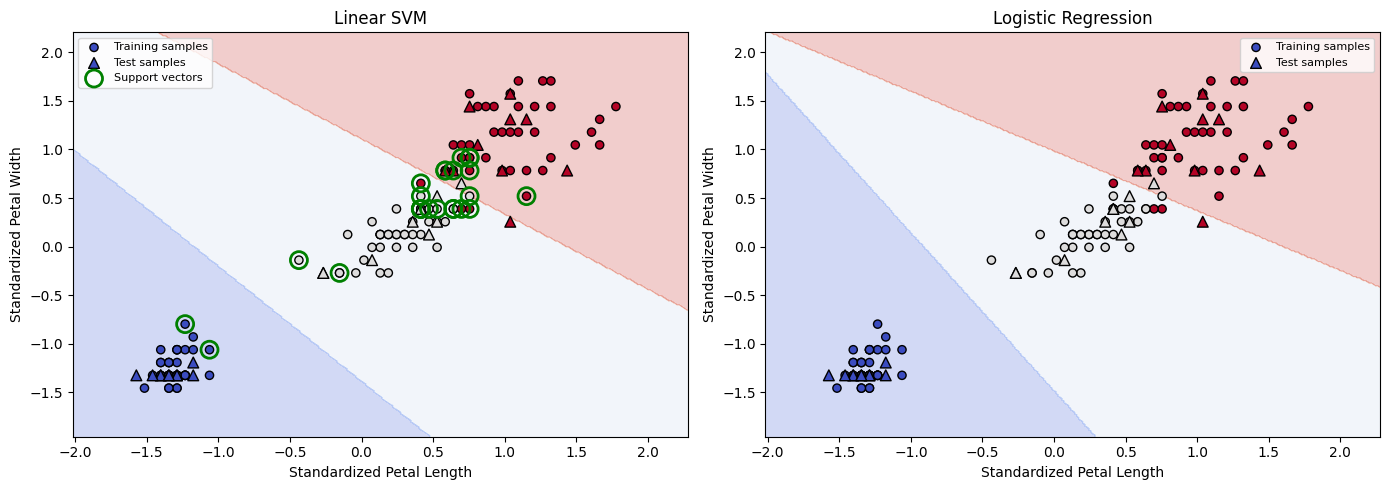

In [2]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix

# 1. Load Iris dataset directly from a URL
url = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/iris.csv"
df = pd.read_csv(url)

print("First five rows:")
print(df.head())


df = df.drop(columns=["Id"], errors="ignore")


X = df[["petal_length", "petal_width"]].values

y = pd.factorize(df["species"])[0]

# 2. Split dataset into training and testing sets
indices = np.arange(len(df))

X_train, X_test, y_train, y_test, idx_train, idx_test = (
    train_test_split(
        X, y, indices,
        test_size=0.2,
        random_state=42,
        stratify=y
    )
)


scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 3. Train Linear SVM and Logistic Regression
svm_model = SVC(kernel="linear", C=1.0)
svm_model.fit(X_train_scaled, y_train)

lr_model = LogisticRegression(max_iter=1000)
lr_model.fit(X_train_scaled, y_train)

# 4. Print support vectors
print("\nSupport vector indices (training set):")
print(svm_model.support_)

original_support_indices = idx_train[svm_model.support_]

print("\nSupport vector indices (original dataset):")
print(original_support_indices)

print("\nSupport vector coordinates (standardized):")
print(svm_model.support_vectors_)

print("\nSupport vector coordinates (original units):")
print(X[original_support_indices])

print("\nSupport vectors per class:")
print(svm_model.n_support_)

# 5. Evaluate both models
svm_pred = svm_model.predict(X_test_scaled)
lr_pred = lr_model.predict(X_test_scaled)

print("\nSVM Accuracy:",
      round(accuracy_score(y_test, svm_pred), 4))
print("Logistic Regression Accuracy:",
      round(accuracy_score(y_test, lr_pred), 4))

print("\nSVM Confusion Matrix:")
print(confusion_matrix(y_test, svm_pred))

print("\nLogistic Regression Confusion Matrix:")
print(confusion_matrix(y_test, lr_pred))

# Generate decision-boundary grid
x_min = X_train_scaled[:, 0].min() - 0.5
x_max = X_train_scaled[:, 0].max() + 0.5
y_min = X_train_scaled[:, 1].min() - 0.5
y_max = X_train_scaled[:, 1].max() + 0.5

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 300),
    np.linspace(y_min, y_max, 300)
)

grid = np.c_[xx.ravel(), yy.ravel()]

svm_grid = svm_model.predict(grid).reshape(xx.shape)
lr_grid = lr_model.predict(grid).reshape(xx.shape)

# Plot both decision boundaries
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, model, predictions, title in [
    (axes[0], svm_model, svm_grid, "Linear SVM"),
    (axes[1], lr_model, lr_grid, "Logistic Regression")
]:
    ax.contourf(
        xx, yy, predictions,
        alpha=0.25, cmap=plt.cm.coolwarm
    )

    ax.scatter(
        X_train_scaled[:, 0], X_train_scaled[:, 1],
        c=y_train, cmap=plt.cm.coolwarm,
        edgecolors="black", s=35,
        label="Training samples"
    )

    ax.scatter(
        X_test_scaled[:, 0], X_test_scaled[:, 1],
        c=y_test, cmap=plt.cm.coolwarm,
        marker="^", edgecolors="black", s=60,
        label="Test samples"
    )

    if title == "Linear SVM":
        ax.scatter(
            model.support_vectors_[:, 0],
            model.support_vectors_[:, 1],
            s=150, facecolors="none",
            edgecolors="green", linewidths=2,
            label="Support vectors"
        )

    ax.set_title(title)
    ax.set_xlabel("Standardized Petal Length")
    ax.set_ylabel("Standardized Petal Width")
    ax.legend(fontsize=8)

plt.tight_layout()
plt.show()
